# PlantVillage — Transfer Learning with EfficientNetB0

This notebook evaluates transfer learning using a pretrained EfficientNetB0 model for the 38-class PlantVillage disease classification task.

The experiment is divided into two stages:

1. **Feature extraction** — freeze the pretrained EfficientNetB0 backbone and train a new classification head.
2. **Fine-tuning** — unfreeze selected upper layers of the backbone and continue training with a lower learning rate.

The results will be compared against the baseline CNN established in the previous notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "plantvillage"
MODEL_DIR = PROJECT_ROOT / "models"

TRAIN_PATH = DATA_DIR / "train.csv"
VAL_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (256, 256)
BATCH_SIZE = 32

FEATURE_EPOCHS = 8
FINE_TUNE_EPOCHS = 10

RANDOM_SEED = 42

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("TensorFlow:", tf.__version__)
print("Image size:", IMG_SIZE)

TensorFlow: 2.22.0-rc0
Image size: (256, 256)


In [3]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Training images:   {len(train_df):,}")
print(f"Validation images: {len(val_df):,}")
print(f"Test images:       {len(test_df):,}")

Training images:   38,012
Validation images: 8,146
Test images:       8,146


In [4]:
class_ids = sorted(train_df["class_id"].unique())

class_to_index = {
    class_id: index
    for index, class_id in enumerate(class_ids)
}

index_to_class = {
    index: class_id
    for class_id, index in class_to_index.items()
}

NUM_CLASSES = len(class_ids)

print("Number of classes:", NUM_CLASSES)

Number of classes: 38


In [6]:
for df in (train_df, val_df, test_df):
    df["label"] = df["class_id"].map(class_to_index)


def resolve_paths(df):
    paths = []

    for path in df["image_path"]:
        image_path = PROJECT_ROOT / path

        if not image_path.exists():
            raise FileNotFoundError(
                f"Image not found: {image_path}"
            )

        paths.append(str(image_path))

    return paths


train_paths = resolve_paths(train_df)
val_paths = resolve_paths(val_df)
test_paths = resolve_paths(test_df)

print("Labels and image paths prepared.")

Labels and image paths prepared.


In [7]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(paths, labels, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [8]:
train_dataset = create_dataset(
    train_paths,
    train_df["label"].values,
    shuffle=True,
)

val_dataset = create_dataset(
    val_paths,
    val_df["label"].values,
)

test_dataset = create_dataset(
    test_paths,
    test_df["label"].values,
)

print("Datasets created.")

Datasets created.


In [9]:
images, labels = next(iter(train_dataset))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(images)),
    "to",
    float(tf.reduce_max(images)),
)

Image batch: (32, 256, 256, 3)
Label batch: (32,)
Pixel range: 0.0 to 255.0


In [10]:
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMG_SIZE, 3),
)

base_model.trainable = False

print("Backbone layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Backbone layers: 238


In [11]:
inputs = layers.Input(shape=(*IMG_SIZE, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
)(x)

model = models.Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [13]:
history_feature = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=FEATURE_EPOCHS,
)

Epoch 1/8


/Users/devangvamja/Documents/Projects/agrivision-ai/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 360s 301ms/step - accuracy: 0.9028 - loss: 0.4535 - val_accuracy: 0.9554 - val_loss: 0.1804
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 402s 339ms/step - accuracy: 0.9704 - loss: 0.1276 - val_accuracy: 0.9726 - val_loss: 0.1125
Epoch 3/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 410s 345ms/step - accuracy: 0.9800 - loss: 0.0849 - val_accuracy: 0.9758 - val_loss: 0.0887
Epoch 4/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 436s 367ms/step - accuracy: 0.9858 - loss: 0.0627 - val_accuracy: 0.9777 - val_loss: 0.0765
Epoch 5/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 512s 431ms/step - accuracy: 0.9891 - loss: 0.0497 - val_accuracy: 0.9804 - val_loss: 0.0689
Epoch 6/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 533s 449ms/step - accuracy: 0.9913 - loss: 0.0405 - val_accuracy: 0.9813 - val_loss: 0.0630
Epoch 7/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 528s 445ms/step - accuracy: 0.9929 - loss: 0.0336 - val_accuracy: 0.9828 - val_loss: 0.0578
Epoch 8/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 546s 459ms/step - accuracy: 0.9943 - l

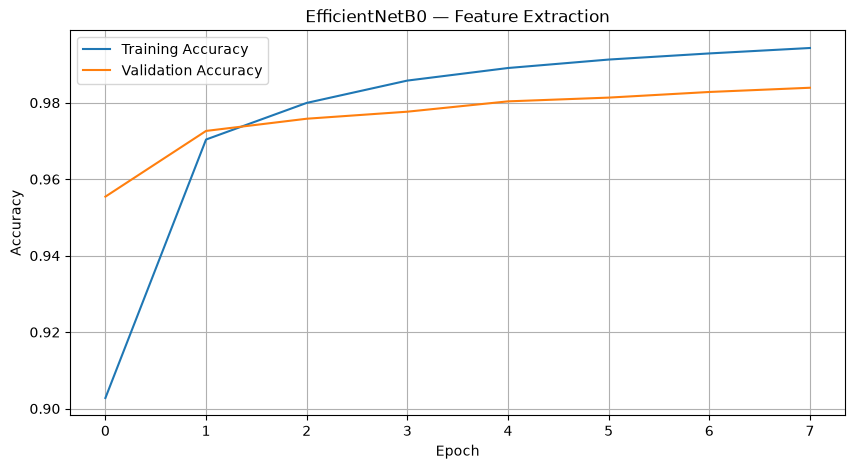

In [14]:
feature_history = pd.DataFrame(
    history_feature.history
)

plt.figure(figsize=(10, 5))

plt.plot(
    feature_history["accuracy"],
    label="Training Accuracy",
)

plt.plot(
    feature_history["val_accuracy"],
    label="Validation Accuracy",
)

plt.title("EfficientNetB0 — Feature Extraction")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

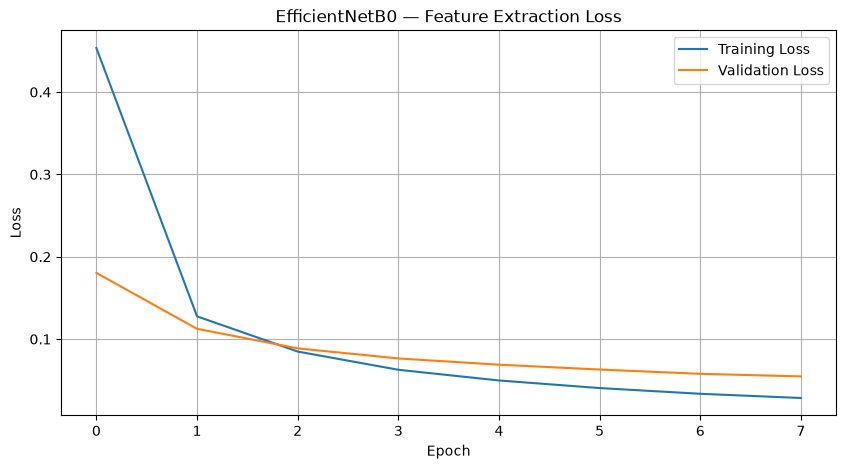

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    feature_history["loss"],
    label="Training Loss",
)

plt.plot(
    feature_history["val_loss"],
    label="Validation Loss",
)

plt.title("EfficientNetB0 — Feature Extraction Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
base_model.trainable = True

In [17]:
fine_tune_from = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model.layers[fine_tune_from:]:
    layer.trainable = True

print(
    "Trainable backbone layers:",
    sum(
        layer.trainable
        for layer in base_model.layers
    )
)

Trainable backbone layers: 30


In [18]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [19]:
history_fine = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=FINE_TUNE_EPOCHS,
)

Epoch 1/10


/Users/devangvamja/Documents/Projects/agrivision-ai/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 472s 395ms/step - accuracy: 0.9965 - loss: 0.0164 - val_accuracy: 0.9849 - val_loss: 0.0452
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 556s 468ms/step - accuracy: 0.9976 - loss: 0.0107 - val_accuracy: 0.9855 - val_loss: 0.0423
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 551s 464ms/step - accuracy: 0.9985 - loss: 0.0077 - val_accuracy: 0.9856 - val_loss: 0.0410
Epoch 4/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 571s 481ms/step - accuracy: 0.9993 - loss: 0.0053 - val_accuracy: 0.9864 - val_loss: 0.0393
Epoch 5/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 557s 469ms/step - accuracy: 0.9994 - loss: 0.0040 - val_accuracy: 0.9851 - val_loss: 0.0449
Epoch 6/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 567s 477ms/step - accuracy: 0.9997 - loss: 0.0030 - val_accuracy: 0.9867 - val_loss: 0.0417
Epoch 7/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 560s 471ms/step - accuracy: 0.9999 - loss: 0.0021 - val_accuracy: 0.9874 - val_loss: 0.0415
Epoch 8/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 546s 460ms/step - accuracy: 0.9

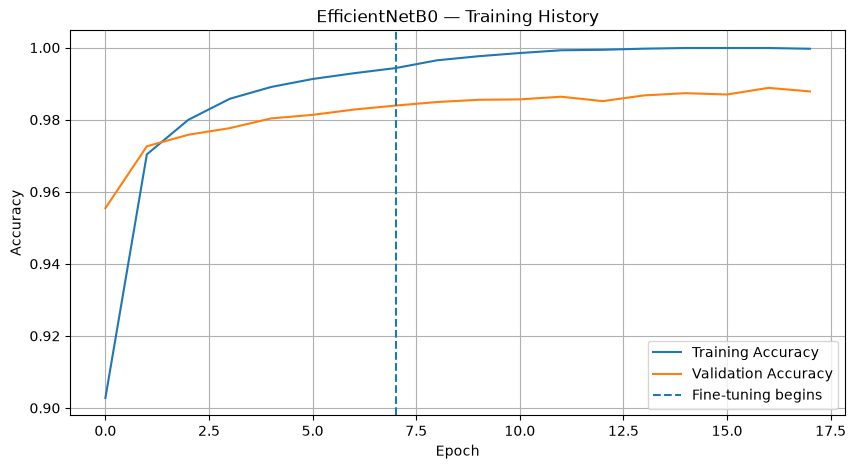

In [20]:
feature_acc = history_feature.history["accuracy"]
feature_val_acc = history_feature.history["val_accuracy"]

fine_acc = history_fine.history["accuracy"]
fine_val_acc = history_fine.history["val_accuracy"]

all_train_acc = feature_acc + fine_acc
all_val_acc = feature_val_acc + fine_val_acc

plt.figure(figsize=(10, 5))

plt.plot(
    all_train_acc,
    label="Training Accuracy",
)

plt.plot(
    all_val_acc,
    label="Validation Accuracy",
)

plt.axvline(
    x=FEATURE_EPOCHS - 1,
    linestyle="--",
    label="Fine-tuning begins",
)

plt.title("EfficientNetB0 — Training History")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


In [21]:
test_loss, test_accuracy = model.evaluate(
    test_dataset
)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

255/255 ━━━━━━━━━━━━━━━━━━━━ 59s 229ms/step - accuracy: 0.9883 - loss: 0.0437
Test Loss:     0.0437
Test Accuracy: 0.9883


In [22]:
y_true = []
y_pred = []

for images_batch, labels_batch in test_dataset:
    predictions = model.predict(
        images_batch,
        verbose=0,
    )

    y_true.extend(labels_batch.numpy())
    y_pred.extend(
        np.argmax(predictions, axis=1)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated:", len(y_pred))

Predictions generated: 8146


In [23]:
target_names = [
    train_df.loc[
        train_df["class_id"] == index_to_class[i],
        "class_name"
    ].iloc[0]
    for i in range(NUM_CLASSES)
]

report = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    digits=4,
)

print(report)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9894    0.9894    0.9894        94
                                 Apple___Black_rot     0.9688    1.0000    0.9841        93
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        41
                                   Apple___healthy     1.0000    1.0000    1.0000       247
                               Blueberry___healthy     1.0000    1.0000    1.0000       226
          Cherry_(including_sour)___Powdery_mildew     0.9937    1.0000    0.9968       158
                 Cherry_(including_sour)___healthy     1.0000    1.0000    1.0000       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9221    0.9221    0.9221        77
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000       179
               Corn_(maize)___Northern_Leaf_Blight     0.9524    0.9524    0.95

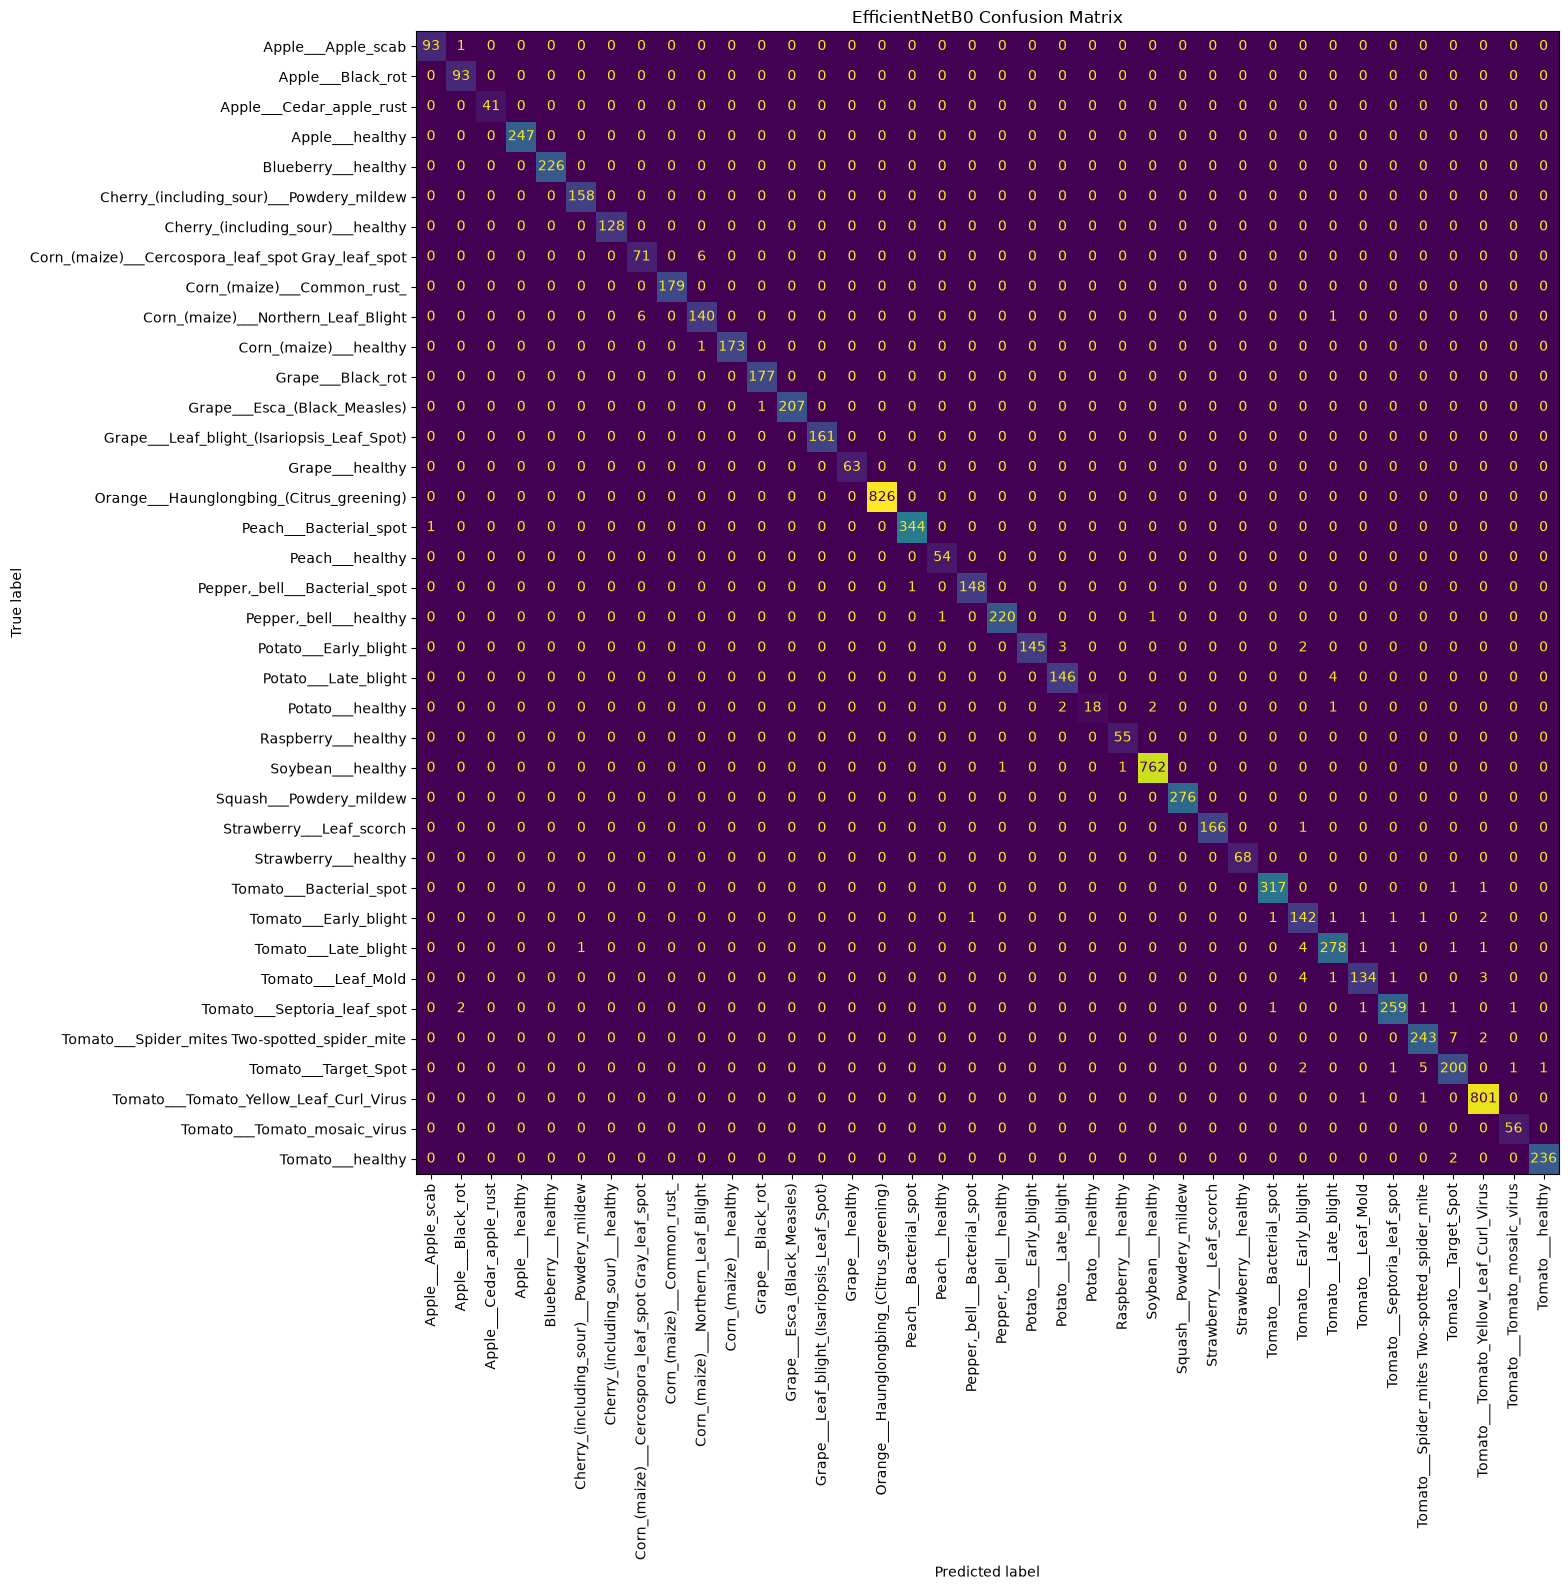

In [24]:
cm = confusion_matrix(
    y_true,
    y_pred,
)

fig, ax = plt.subplots(figsize=(16, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names,
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False,
)

plt.title(
    "EfficientNetB0 Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [25]:
report_dict = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    output_dict=True,
)

class_performance = (
    pd.DataFrame(report_dict)
    .T
    .loc[
        target_names,
        ["precision", "recall", "f1-score", "support"],
    ]
    .sort_values("f1-score")
)

class_performance.head(10)

,precision,recall,f1-score,support
Potato___healthy,1.000000,0.782609,0.878049,23.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.922078,0.922078,0.922078,77.0
Tomato___Early_blight,0.916129,0.946667,0.931148,150.0
Tomato___Target_Spot,0.943396,0.952381,0.947867,210.0
Corn_(maize)___Northern_Leaf_Blight,0.952381,0.952381,0.952381,147.0
Tomato___Leaf_Mold,0.971014,0.937063,0.953737,143.0
Tomato___Spider_mites Two-spotted_spider_mite,0.968127,0.964286,0.966203,252.0
Potato___Late_blight,0.966887,0.973333,0.970100,150.0
Tomato___Late_blight,0.972028,0.968641,0.970332,287.0
Tomato___Septoria_leaf_spot,0.984791,0.973684,0.979206,266.0


In [26]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "EfficientNetB0",
    ],
    "Test Accuracy": [
        0.9368,
        test_accuracy,
    ],
})

comparison

,Model,Test Accuracy
0,Baseline CNN,0.936800
1,EfficientNetB0,0.988338


In [27]:
MODEL_PATH = MODEL_DIR / "plantvillage_efficientnetb0.keras"

model.save(MODEL_PATH)

print(f"✓ Model saved to: {MODEL_PATH}")

✓ Model saved to: /Users/devangvamja/Documents/Projects/agrivision-ai/models/plantvillage_efficientnetb0.keras


## Transfer Learning Findings

EfficientNetB0 substantially outperformed the baseline CNN on the PlantVillage disease-classification task.

The final model achieved a test accuracy of **98.83%** and a macro F1-score of **98.26%**, compared with **93.68%** test accuracy and **91.36%** macro F1-score for the baseline CNN.

This represents an improvement of **5.15 percentage points in test accuracy** and **6.90 percentage points in macro F1-score**.

The improvement was particularly significant for classes that were difficult for the baseline model. Corn Cercospora Leaf Spot / Gray Leaf Spot improved from an F1-score of **65.08%** to **92.21%**. Tomato Early Blight improved from **73.88%** to **93.11%**, while Potato Late Blight improved from **82.04%** to **97.01%**.

The final confusion matrix shows substantially fewer classification errors across the 38 classes. Most classes achieved F1-scores above 95%.

The training curves show a small gap between training and validation performance during fine-tuning, indicating some mild overfitting. However, the high test performance demonstrates strong generalization on the held-out test set.

### Model Selection

Based on the current evaluation, EfficientNetB0 is selected as the best-performing PlantVillage disease-classification model and will be used as the candidate model for subsequent explainability and deployment work.

Further model optimization will only be considered if error analysis identifies a specific limitation that justifies additional complexity.